In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten, Dense, Conv2D, MaxPool2D, Activation,  Dropout,LSTM,Embedding,Layer, LSTM, Conv1D, MaxPool1D, TimeDistributed, Input, GRU
# from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras import metrics
from tensorflow.keras.callbacks import Callback
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model, load_model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from tensorflow.keras.utils import plot_model
from scipy import signal
from keras.layers.rnn.dropout_rnn_cell_mixin import DropoutRNNCellMixin
import keras_tuner as kt
import keras_lmu
from sklearn.model_selection import train_test_split
#import torch
import tensorflow.keras as keras
import tensorflow.keras.backend as keras_backend
import second_gen_RNN
import third_gen_RLIF
import random
%matplotlib qt

In [4]:
meta_loss_RNN  = np.genfromtxt(r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Loss_info_SNN_HSNN_RNN\meta_loss_RNN_dropout_10_percent.csv", delimiter=',')
meta_loss_SNN  = np.genfromtxt(r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Loss_info_SNN_HSNN_RNN\meta_loss_SNN.csv", delimiter=',')
meta_loss_HSNN = np.genfromtxt(r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Loss_info_SNN_HSNN_RNN\meta_loss_HSNN.csv", delimiter=',')
meta_loss_RNN_no_dropout  = np.genfromtxt(r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Loss_info_SNN_HSNN_RNN\meta_loss_RNN_no_dropout.csv", delimiter=',')
meta_loss_QAT             = np.genfromtxt(r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Loss_info_SNN_HSNN_RNN\meta_loss_QAT_HSNN.csv", delimiter=',')

In [5]:
test_loss_RNN  = np.genfromtxt(r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Loss_info_SNN_HSNN_RNN\test_loss_RNN_dropout_10_percent.csv", delimiter=',')
test_loss_SNN  = np.genfromtxt(r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Loss_info_SNN_HSNN_RNN\test_loss_SNN.csv", delimiter=',')
test_loss_HSNN = np.genfromtxt(r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Loss_info_SNN_HSNN_RNN\val_loss_HSNN.csv", delimiter=',')
test_loss_RNN_no_dropout = np.genfromtxt(r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Loss_info_SNN_HSNN_RNN\test_loss_RNN_no_dropout.csv", delimiter=',')
test_loss_QAT            = np.genfromtxt(r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Loss_info_SNN_HSNN_RNN\test_loss_QAT_HSNN.csv", delimiter=',')

In [15]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# Define figure size and DPI for high-quality output
fig, ax = plt.subplots(figsize=(8, 6))

# Main plots with distinct markers
ax.plot(test_loss_RNN[0:100], label='Test loss RNN with dropout', linestyle='-', marker='o', markersize=5, linewidth=2, color='#1f77b4')
ax.plot(test_loss_HSNN[0:100], label='Test loss HSNN', linestyle='--', marker='s', markersize=5, linewidth=2, color='#ff7f0e')
ax.plot(test_loss_SNN[0:100], label='Test loss SNN', linestyle='-.', marker='d', markersize=5, linewidth=2, color='#2ca02c')
ax.plot(test_loss_RNN_no_dropout[0:100], label='Test loss RNN without dropout', linestyle='-', marker='x', markersize=5, linewidth=2, color='#d62728')
ax.plot(test_loss_QAT, label = 'Test loss HSNN with QAT', linestyle = '--', marker = 's',markersize=5, linewidth=2, color = '#9467bd')

# Add main labels
ax.set_xlabel('Epochs', fontsize=14)
ax.set_ylabel('Loss', fontsize=14)
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax.ticklabel_format(axis='x', style='sci', scilimits=(0, 0))
ax.grid(True, linestyle='--', alpha=0.6)
#ax.legend(fontsize=12, loc='upper left', bbox_to_anchor=(1, 1))

# Create inset zoomed-in area
axins = inset_axes(ax, width="45%", height="45%", loc='center right')  # Adjust size and position

# Plot same data but zoomed into a specific range
zoom_range = slice(39, 59)  # Change this to focus on a specific region
axins.set_xlim(zoom_range.start, zoom_range.stop)
axins.plot(range(39, 59), test_loss_RNN[zoom_range], linestyle='-', marker='o', markersize=5, linewidth=2, color='#1f77b4')
axins.plot(range(39, 59), test_loss_HSNN[zoom_range], linestyle='--', marker='s', markersize=5, linewidth=2, color='#ff7f0e')
axins.plot(range(39, 59), test_loss_SNN[zoom_range], linestyle='-.', marker='d', markersize=5, linewidth=2, color='#2ca02c')
axins.plot(range(39, 59), test_loss_RNN_no_dropout[zoom_range], linestyle='-.', marker='d', markersize=5, linewidth=2, color='#d62728')
axins.plot(range(39,59), test_loss_QAT[zoom_range], linestyle = '--', marker = 's',markersize=5, linewidth=2, color = '#9467bd')

#axins1 = inset_axes(ax, width="40%", height="40%", loc='lower right')  # Adjust size and position

# Plot same data but zoomed into a specific range
# zoom_range1 = slice(70, 100)  # Change this to focus on a specific region
# axins1.plot(meta_loss_RNN[zoom_range1], linestyle='-', marker='o', markersize=5, linewidth=2, color='#1f77b4')
# axins1.plot(meta_loss_HSNN[zoom_range1], linestyle='--', marker='s', markersize=5, linewidth=2, color='#ff7f0e')
# axins1.plot(meta_loss_SNN[zoom_range1], linestyle='-.', marker='d', markersize=5, linewidth=2, color='#2ca02c')

# Set limits for zoomed-in plot
#axins.set_xlim(zoom_range.start, zoom_range.stop)
# axins.set_ylim(min(min(meta_loss_RNN[zoom_range]), min(meta_loss_HSNN[zoom_range]), min(meta_loss_SNN[zoom_range])) * 0.95, 
#                max(max(meta_loss_RNN[zoom_range]), max(meta_loss_HSNN[zoom_range]), max(meta_loss_SNN[zoom_range])) * 1.05)  # Auto-adjusted y-axis

# axins.set_ylim(0, max(val_loss_HSNN_ANN[zoom_range]))  # Adjust based on your data
# axins.set_xticks([])  # Remove x-ticks for clarity
# axins.set_yticks([])  # Remove y-ticks for clarity

# Add a rectangle in the main plot showing the zoomed area
mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="black", linestyle="--")

# Final adjustments
#plt.tight_layout()
ax.legend(fontsize=12, loc='best', frameon=True)

plt.show()
plt.savefig(r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Plots\Test_loss_QAT_inklusive.pdf", format="pdf", bbox_inches="tight")
plt.savefig(r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Plots\Test_loss_QAT_inklusive.svg", format="svg", bbox_inches="tight")




In [ ]:
meta_loss_HSNN[-1]

In [ ]:
np.sqrt(0.00025838325)

In [ ]:
import numpy as np

def quantize_weights(weights, num_bits=8):
    """
    Quantizes the given weights to the specified bit-width.

    Parameters:
    - weights: np.ndarray, original floating-point weights.
    - num_bits: int, bit-width for quantization (e.g., 8 or 16).

    Returns:
    - quantized_weights: np.ndarray, quantized integer weights.
    - scale: float, scaling factor used for quantization.
    """
    # Determine the maximum representable value based on num_bits
    max_int = 2**(num_bits - 1) - 1

    # Compute scaling factor
    max_weight = np.max(np.abs(weights))
    scale = max_int / max_weight if max_weight != 0 else 1

    # Quantize weights
    quantized_weights = np.round(weights * scale).astype(np.int32)

    # Clip to ensure within representable range
    quantized_weights = np.clip(quantized_weights, -max_int, max_int)

    return quantized_weights, scale

# Example usage:
original_weights = np.array([0.1, -0.5, 0.3, -0.8], dtype=np.float32)
quantized_weights, scale = quantize_weights(original_weights, num_bits=8)
print("Quantized Weights:", quantized_weights)
print("Scaling Factor:", scale)



In [2]:
cell = GSN(1100)

quantized_layer = tf.keras.layers.RNN(cell)

In [5]:
quantized_layer(tf.random.uniform(shape=(1,1,5))).numpy().max()

0.0

In [ ]:
quantized_layer.get_weights()

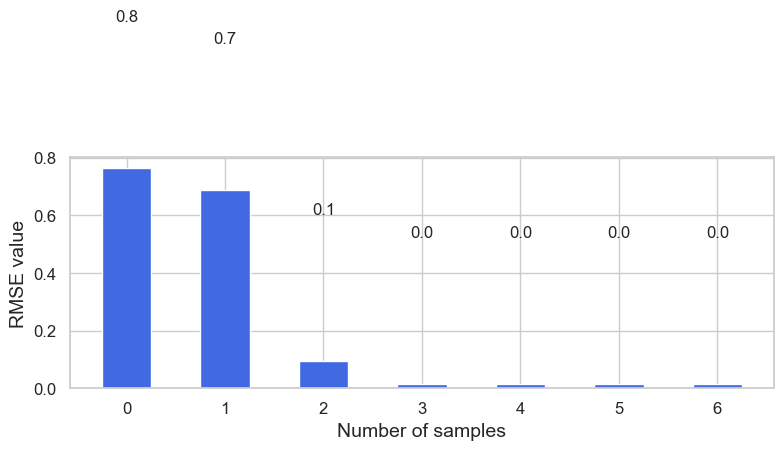

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Corrected data
x = np.array([0, 1, 2, 3, 4, 5, 6])
y = np.array([0.7631, 0.6881, 0.093941, 0.0140, 0.0142, 0.0133, 0.0131])

# Set scientific style
sns.set_theme(style="whitegrid")

# Create the plot
plt.figure(figsize=(8, 6))

# All bars with same color (e.g., blue)
bar_color = 'royalblue'
bars = plt.bar(x, y, color=bar_color, width=0.5)

# Add labels and title
plt.xlabel('Number of samples', fontsize=14)
plt.ylabel('RMSE value', fontsize=14)
#plt.title('Scientific Bar Plot', fontsize=16)

# Set limits with some margin
#plt.ylim(min(y) - 50, max(y) + 20)

# Add value labels on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'{yval:.1f}',
             ha='center', va='bottom', fontsize=12)

# Ticks
plt.xticks(x, fontsize=12)
plt.yticks(fontsize=12)

# Tight layout
plt.tight_layout()

# Show plot
plt.show()

# plt.savefig(r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Plots\self-learning_steps_vs_frozen_layers.pdf", format="pdf", bbox_inches="tight")
# plt.savefig(r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Plots\self-learning_steps_vs_frozen_layers.svg", format="svg", bbox_inches="tight")

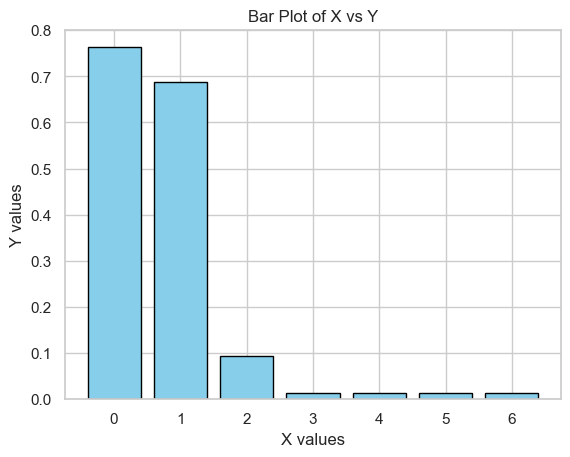

In [30]:
import numpy as np
import matplotlib.pyplot as plt

# Data
x = np.array([0, 1, 2, 3, 4, 5, 6])
y = np.array([0.7631, 0.6881, 0.093941, 0.0140, 0.0142, 0.0133, 0.0131])

# Create bar plot
plt.bar(x, y, color='skyblue', edgecolor='black')

# Add labels and title
plt.xlabel('X values')
plt.ylabel('Y values')
plt.title('Bar Plot of X vs Y')

# Show the plot
plt.show()


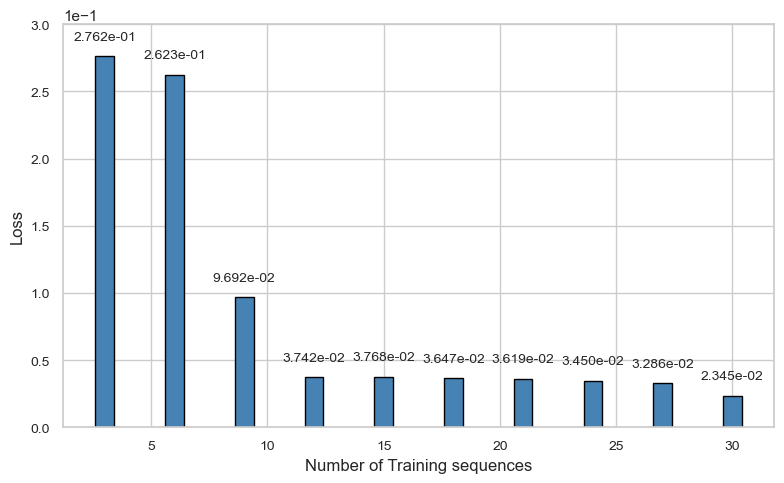

In [40]:
import numpy as np
import matplotlib.pyplot as plt

# Data
x = np.array([3, 6, 9, 12, 15, 18, 21, 24, 27, 30])
y = np.sqrt(np.array([0.7631, 0.6881, 0.093941, 0.0140, 0.0142, 0.0133, 0.0131, 0.0119, 0.0108, 0.0055])*0.1)

# Set up figure and axes
fig, ax = plt.subplots(figsize=(8, 5))

# Create bar plot
bars = ax.bar(x, y, color='royalblue', edgecolor='black')

# Annotate values on bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height + 0.01, f'{height:.3e}',
            ha='center', va='bottom', fontsize=10)

# Axis labels and title
ax.set_xlabel('Number of Training sequences', fontsize=12)
ax.set_ylabel('Loss', fontsize=12)

# Use scientific notation for y-axis
ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
plt.ylim(0, 3e-1)

# Clean up plot appearance
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()

# Show the plot
plt.show()

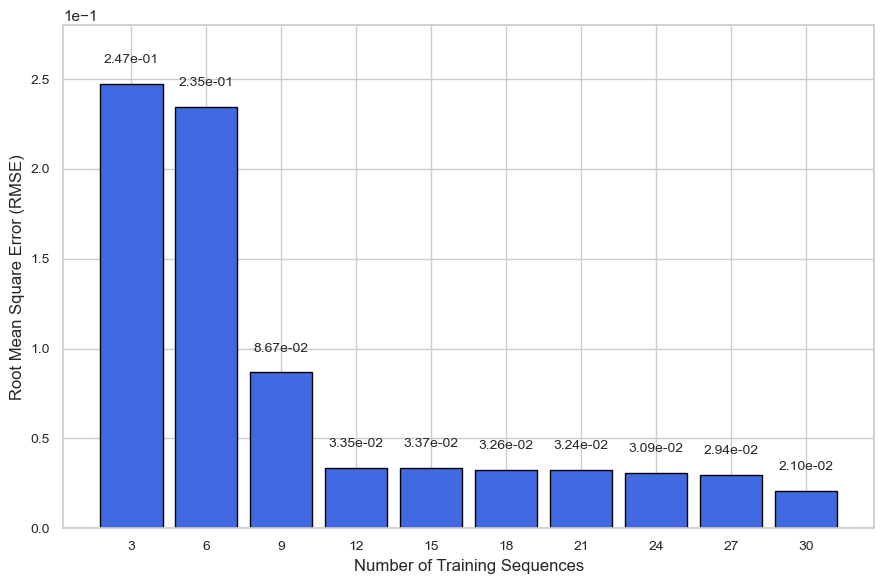

In [55]:
import numpy as np
import matplotlib.pyplot as plt

# Updated data
x = np.array([3, 6, 9, 12, 15, 18, 21, 24, 27, 30])
y = np.sqrt(np.array([0.7631, 0.6881, 0.093941, 0.0140, 0.0142, 0.0133, 0.0131, 0.0119, 0.0108, 0.0055])*0.08)

# Set up figure and axes
fig, ax = plt.subplots(figsize=(9, 6))

# Create bar plot
bars = ax.bar(x, y, width=2.5, color='royalblue', edgecolor='black')  # Adjust width to avoid overlap

# Annotate values on bars in scientific notation
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height + 0.01, f'{height:.2e}',
            ha='center', va='bottom', fontsize=10)

# X-axis labels and ticks
ax.set_xticks(x)
ax.set_xticklabels([f"{val}" for val in x], fontsize=10)

# Axis labels and title
ax.set_xlabel('Number of Training Sequences', fontsize=12)
ax.set_ylabel('Root Mean Square Error (RMSE)', fontsize=12)


# Use scientific notation for y-axis
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

# Improve layout
plt.yticks(fontsize=10)
plt.tight_layout()
plt.ylim(0, 2.8e-1)

# Show plot


plt.savefig(r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Plots\comparison_of_meta_and_transfer_learning.pdf", format="pdf", bbox_inches="tight")
plt.savefig(r"C:\Users\Tandale\sciebo\olddata\PostDoc\Writing\Meta_Learning\Plots\comparison_of_meta_and_transfer_learning.svg", format="svg", bbox_inches="tight")

In [ ]:
input_nn_train